In [1]:
CSV_PATH='/home/gmvaz/2026_GEMs/stm_model_test/nutrient_sweep'

In [2]:
import polars as pl
import matplotlib.pyplot as plt

# Explore the output of the Combinatorial Nutrient Sweep Study

In [3]:
# read in all csvs
all_df = pl.scan_csv(CSV_PATH, include_file_paths='filename').collect()

In [4]:
# Read in all csvs and exclude the FBA run when the nutrient reaction value is 0
all_df = all_df.filter(pl.col('nutrient_rxn_value') > 0.0)

## See results from one model, medium, and nutrient

In [5]:
all_df.filter((pl.col('model') == 'stm_1090') &
              (pl.col('medium_condition') == 'B_infection_medium') &
              (pl.col('nutrient_rxn') == 'EX_tet_e'))

,model,medium_condition,nutrient_rxn,nutrient_rxn_value,status,objective_value,filename
i64,str,str,str,f64,str,f64,str
1,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",1.414214,"""optimal""",0.81712,"""/home/gmvaz/2026_GEMs/stm_mode…"
2,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",1.951097,"""optimal""",0.827743,"""/home/gmvaz/2026_GEMs/stm_mode…"
3,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",2.6918,"""optimal""",0.842374,"""/home/gmvaz/2026_GEMs/stm_mode…"
4,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",3.7137,"""optimal""",0.862594,"""/home/gmvaz/2026_GEMs/stm_mode…"
5,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",5.123547,"""optimal""",0.890514,"""/home/gmvaz/2026_GEMs/stm_mode…"
…,…,…,…,…,…,…,…
11,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",35.330864,"""optimal""",1.397904,"""/home/gmvaz/2026_GEMs/stm_mode…"
12,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",48.743666,"""optimal""",1.497674,"""/home/gmvaz/2026_GEMs/stm_mode…"
13,"""stm_1090""","""B_infection_medium""","""EX_tet_e""",67.248425,"""optimal""",1.618669,"""/home/gmvaz/2026_GEMs/stm_mode…"


## Can we find and exclude collections of (models, medium_condition, nutrients) where nothing changes

This is sort of SQL-like, sqlite3 is something Kush probably uses.

In [6]:
# group results by model, medium, nutrient reaction and create new columns for the minumum and maximum objective value
boring_mixes = all_df.group_by(['medium_condition', 'model', 'nutrient_rxn']).agg(
    min_obj=pl.col('objective_value').min(),
    max_obj=pl.col('objective_value').max(),
    status=pl.col('status').unique()
)
boring_mixes

medium_condition,model,nutrient_rxn,min_obj,max_obj,status
str,str,str,f64,f64,list[str]
"""G_infection_medium""","""stm_1585""","""EX_12ppd__S_e""",0.964613,0.964674,"[""optimal""]"
"""E_infection_medium""","""stm_1090""","""EX_ac_e""",0.927604,0.927642,"[""optimal""]"
"""G_infection_medium""","""stm_1585""","""EX_lac__L_e""",0.96463,0.964674,"[""optimal""]"
"""G_infection_medium""","""mixed_stm1585""","""EX_ac_e""",0.963248,0.963323,"[""optimal""]"
"""A_infection_medium""","""mixed_stm2575""","""EX_no3_e""",0.867522,2.99236,"[""optimal""]"
…,…,…,…,…,…
"""B_infection_medium""","""mixed_stm2575""","""EX_for_e""",0.852242,0.85228,"[""optimal""]"
"""A_infection_medium""","""stm_1585""","""EX_pyr_e""",0.777108,1.719637,"[""optimal""]"
"""G_infection_medium""","""stm_2575""","""EX_no3_e""",0.98592,3.065853,"[""optimal""]"


In [7]:
# keep all experiments where the highest and lowest objective value are the same 
boring_mixes = boring_mixes.filter(pl.col('min_obj').round(2) == pl.col('max_obj').round(2))
boring_mixes

medium_condition,model,nutrient_rxn,min_obj,max_obj,status
str,str,str,f64,f64,list[str]
"""G_infection_medium""","""stm_1585""","""EX_12ppd__S_e""",0.964613,0.964674,"[""optimal""]"
"""E_infection_medium""","""stm_1090""","""EX_ac_e""",0.927604,0.927642,"[""optimal""]"
"""G_infection_medium""","""stm_1585""","""EX_lac__L_e""",0.96463,0.964674,"[""optimal""]"
"""G_infection_medium""","""mixed_stm1585""","""EX_ac_e""",0.963248,0.963323,"[""optimal""]"
"""D_infection_medium""","""mixed_stm2575""","""EX_12ppd__R_e""",0.891989,0.892072,"[""optimal""]"
…,…,…,…,…,…
"""C_infection_medium""","""stm_2575""","""EX_12ppd__S_e""",0.865568,0.865617,"[""optimal""]"
"""A_infection_medium""","""stm_1585""","""EX_for_e""",0.841134,0.841134,"[""optimal""]"
"""A_infection_medium""","""mixed_stm1585""","""EX_ppa_e""",0.839168,0.839243,"[""optimal""]"


If the lowest and highest are the same then we are assuming there was no change but there's a chance that the highest and lowest value are the same because we've excluded the objective value for each nutrient reaction set to zero. 

## Now that we've found boring mixes, remove them from the original table to define a new table, interesting

In [ ]:

interesting_df = all_df.join(boring_mixes, on=['medium_condition', 'model', 'nutrient_rxn'], how='anti')
interesting_df

,model,medium_condition,nutrient_rxn,nutrient_rxn_value,status,objective_value,filename
i64,str,str,str,f64,str,f64,str
1,"""mixed_stm1090""","""D_infection_medium""","""EX_tet_e""",1.414214,"""optimal""",0.858172,"""/home/gmvaz/2026_GEMs/stm_mode…"
2,"""mixed_stm1090""","""D_infection_medium""","""EX_tet_e""",1.951097,"""optimal""",0.868795,"""/home/gmvaz/2026_GEMs/stm_mode…"
3,"""mixed_stm1090""","""D_infection_medium""","""EX_tet_e""",2.6918,"""optimal""",0.88345,"""/home/gmvaz/2026_GEMs/stm_mode…"
4,"""mixed_stm1090""","""D_infection_medium""","""EX_tet_e""",3.7137,"""optimal""",0.903635,"""/home/gmvaz/2026_GEMs/stm_mode…"
5,"""mixed_stm1090""","""D_infection_medium""","""EX_tet_e""",5.123547,"""optimal""",0.931564,"""/home/gmvaz/2026_GEMs/stm_mode…"
…,…,…,…,…,…,…,…
11,"""stm_2575""","""G_infection_medium""","""EX_tet_e""",35.330864,"""optimal""",1.452376,"""/home/gmvaz/2026_GEMs/stm_mode…"
12,"""stm_2575""","""G_infection_medium""","""EX_tet_e""",48.743666,"""optimal""",1.550506,"""/home/gmvaz/2026_GEMs/stm_mode…"
13,"""stm_2575""","""G_infection_medium""","""EX_tet_e""",67.248425,"""optimal""",1.671631,"""/home/gmvaz/2026_GEMs/stm_mode…"


## Now, summarize the interesting ones by min/max, and add a difference

...so we can see which ones have the biggest change!


In [9]:
# group things by medium/model/nutrient, summarize to min/max/status
interesting_sum_df = interesting_df.group_by(['medium_condition', 'model', 'nutrient_rxn']).agg(
    min_obj=pl.col('objective_value').min(),
    max_obj=pl.col('objective_value').max(),
    status=pl.col('status').unique()
)

# add a column that subtracts min from max and sort by it
interesting_sum_df = interesting_sum_df.with_columns(
    diff_obj=pl.col('max_obj') - pl.col('min_obj')
).sort('diff_obj', descending=True)

# display
interesting_sum_df

medium_condition,model,nutrient_rxn,min_obj,max_obj,status,diff_obj
str,str,str,f64,f64,list[str],f64
"""G_infection_medium""","""mixed_stm2575""","""EX_arab__L_e""",0.685868,3.32026,"[""optimal""]",2.634392
"""G_infection_medium""","""stm_2575""","""EX_arab__L_e""",0.679414,3.3133,"[""optimal""]",2.633887
"""F_infection_medium""","""mixed_stm2575""","""EX_arab__L_e""",0.665992,3.299411,"[""optimal""]",2.63342
"""G_infection_medium""","""mixed_stm1090""","""EX_arab__L_e""",0.704125,3.337154,"[""optimal""]",2.633029
"""F_infection_medium""","""stm_2575""","""EX_arab__L_e""",0.659554,3.292348,"[""optimal""]",2.632794
…,…,…,…,…,…,…
"""B_infection_medium""","""mixed_stm1585""","""EX_etha_e""",0.866155,1.363495,"[""optimal""]",0.497341
"""A_infection_medium""","""stm_1090""","""EX_etha_e""",0.846509,1.343817,"[""optimal""]",0.497308
"""A_infection_medium""","""mixed_stm1585""","""EX_etha_e""",0.841302,1.338337,"[""optimal""]",0.497035


In [10]:
# let's poke and prod this a little bit
with pl.Config(tbl_rows=-1):
    print(interesting_sum_df['nutrient_rxn'].unique())

shape: (10,)
Series: 'nutrient_rxn' [str]
[
	"EX_arab__L_e"
	"EX_galct__D_e"
	"EX_glcr_e"
	"EX_etha_e"
	"EX_tet_e"
	"EX_ppa_e"
	"EX_no3_e"
	"EX_mal__L_e"
	"EX_asp__L_e"
	"EX_pyr_e"
]


## Let's plot a few for a particular model & medium



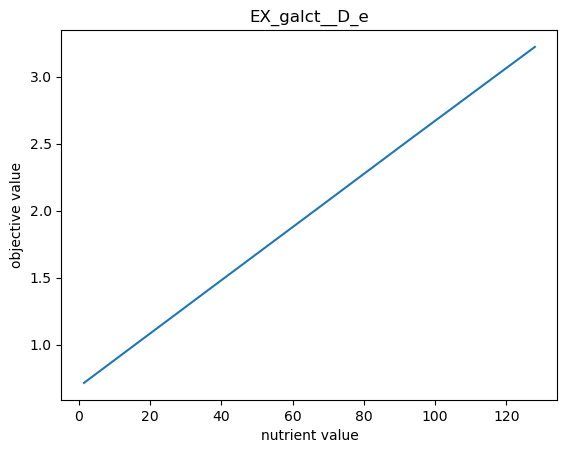

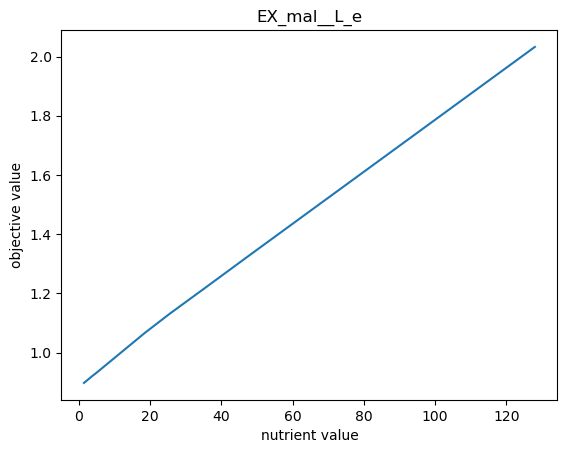

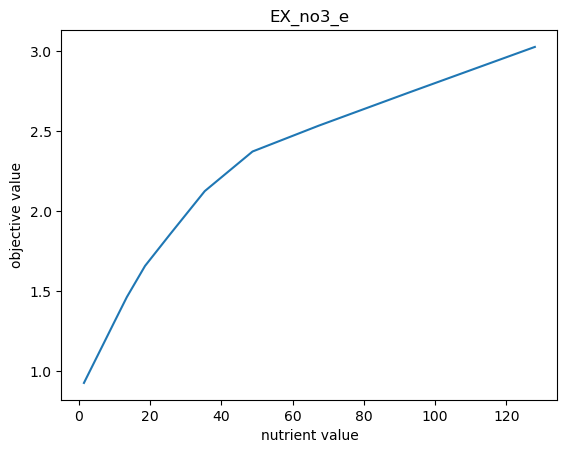

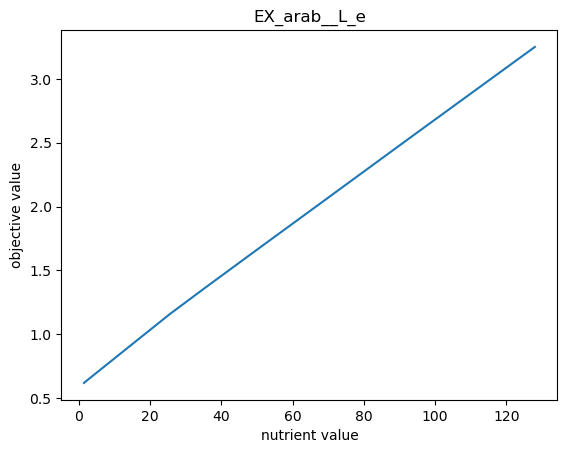

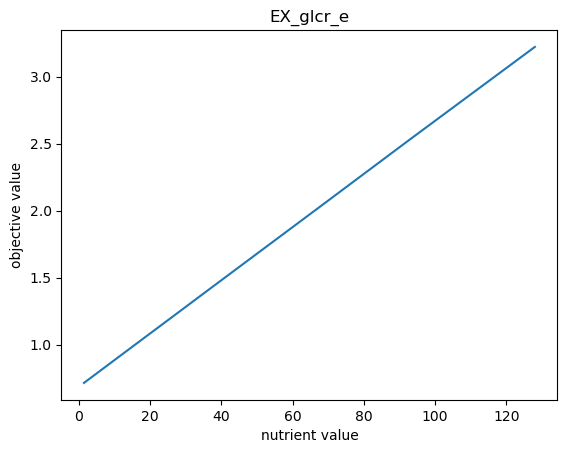

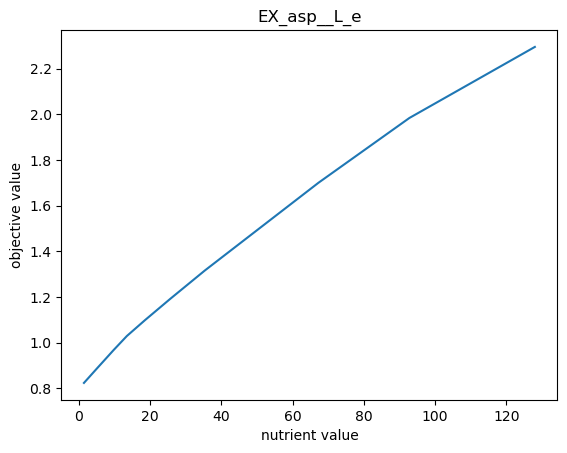

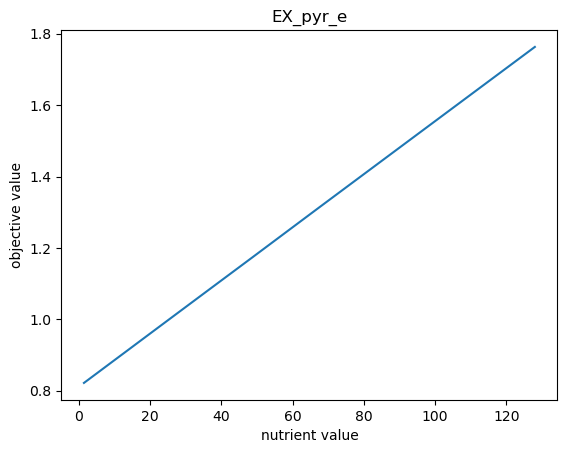

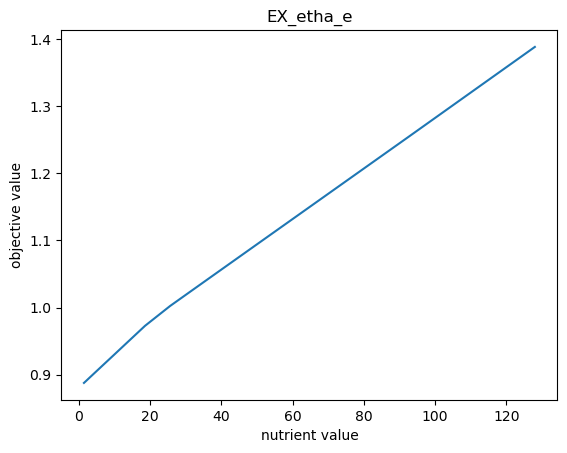

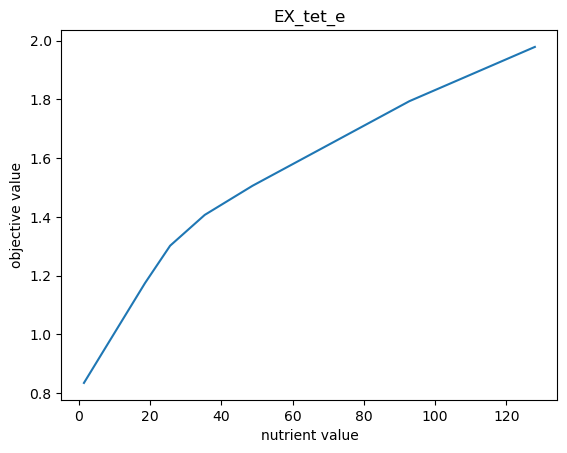

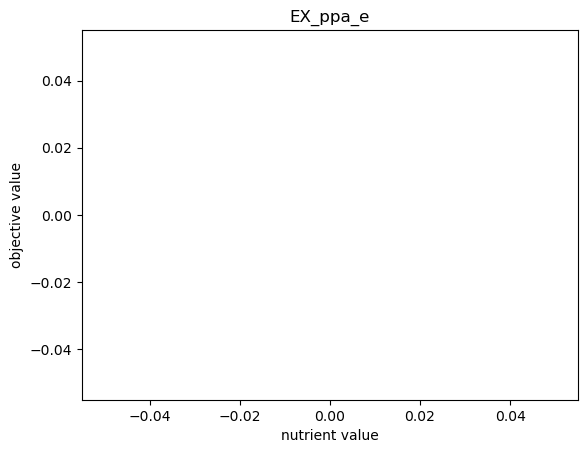

In [11]:
for nutrient in interesting_sum_df['nutrient_rxn'].unique():
    xx_df = interesting_df.filter((pl.col('nutrient_rxn') == nutrient) &
                                  (pl.col('model') == 'stm_2575') &
                                  (pl.col('medium_condition') == 'D_infection_medium'))
    #print(xx_df)
    plt.plot(xx_df['nutrient_rxn_value'], xx_df['objective_value'])
    plt.title(nutrient)
    plt.xlabel('nutrient value')
    plt.ylabel('objective value')
    plt.show()

## Can we pick the model and medium that drive the biggest difference?

In [ ]:
# group things by medium/model/nutrient, summarize to min/max/status
interesting_sum_df = interesting_df.group_by(['medium_condition', 'model', 'nutrient_rxn']).agg(
    min_obj=pl.col('objective_value').min(),
    max_obj=pl.col('objective_value').max(),
    status=pl.col('status').unique()
)

# add a column that subtracts min from max and sort by it
interesting_sum_df = interesting_sum_df.with_columns(
    diff_obj=pl.col('max_obj') - pl.col('min_obj')
).sort('diff_obj', descending=True)

interesting_sum_df

medium_condition,model,nutrient_rxn,min_obj,max_obj,status,diff_obj
str,str,str,f64,f64,list[str],f64
"""G_infection_medium""","""mixed_stm2575""","""EX_arab__L_e""",0.685868,3.32026,"[""optimal""]",2.634392
"""G_infection_medium""","""stm_2575""","""EX_arab__L_e""",0.679414,3.3133,"[""optimal""]",2.633887
"""F_infection_medium""","""mixed_stm2575""","""EX_arab__L_e""",0.665992,3.299411,"[""optimal""]",2.63342
"""G_infection_medium""","""mixed_stm1090""","""EX_arab__L_e""",0.704125,3.337154,"[""optimal""]",2.633029
"""F_infection_medium""","""stm_2575""","""EX_arab__L_e""",0.659554,3.292348,"[""optimal""]",2.632794
…,…,…,…,…,…,…
"""B_infection_medium""","""mixed_stm1585""","""EX_etha_e""",0.866155,1.363495,"[""optimal""]",0.497341
"""A_infection_medium""","""stm_1090""","""EX_etha_e""",0.846509,1.343817,"[""optimal""]",0.497308
"""A_infection_medium""","""mixed_stm1585""","""EX_etha_e""",0.841302,1.338337,"[""optimal""]",0.497035


## Explore places where there are differences within a particular nutrient

In [13]:
sum_sum_df = interesting_sum_df.filter(pl.col('diff_obj') > 1).group_by('nutrient_rxn').agg(
    n_mediums=pl.col('medium_condition').n_unique(),
    n_models=pl.col('model').n_unique()
)

with pl.Config(tbl_rows=-1):
    print(sum_sum_df.sort('n_models'))

shape: (7, 3)
┌───────────────┬───────────┬──────────┐
│ nutrient_rxn  ┆ n_mediums ┆ n_models │
│ ---           ┆ ---       ┆ ---      │
│ str           ┆ u32       ┆ u32      │
╞═══════════════╪═══════════╪══════════╡
│ EX_tet_e      ┆ 7         ┆ 6        │
│ EX_glcr_e     ┆ 7         ┆ 6        │
│ EX_galct__D_e ┆ 7         ┆ 6        │
│ EX_mal__L_e   ┆ 7         ┆ 6        │
│ EX_arab__L_e  ┆ 7         ┆ 6        │
│ EX_asp__L_e   ┆ 7         ┆ 6        │
│ EX_no3_e      ┆ 7         ┆ 6        │
└───────────────┴───────────┴──────────┘


In [ ]:
with pl.Config(tbl_rows=-1):
    print(interesting_sum_df.filter(pl.col('nutrient_rxn') == 'EX_no3_e'))

shape: (42, 7)
┌────────────────────┬───────────────┬──────────────┬──────────┬──────────┬─────────────┬──────────┐
│ medium_condition   ┆ model         ┆ nutrient_rxn ┆ min_obj  ┆ max_obj  ┆ status      ┆ diff_obj │
│ ---                ┆ ---           ┆ ---          ┆ ---      ┆ ---      ┆ ---         ┆ ---      │
│ str                ┆ str           ┆ str          ┆ f64      ┆ f64      ┆ list[str]   ┆ f64      │
╞════════════════════╪═══════════════╪══════════════╪══════════╪══════════╪═════════════╪══════════╡
│ A_infection_medium ┆ stm_2575      ┆ EX_no3_e     ┆ 0.861678 ┆ 2.986719 ┆ ["optimal"] ┆ 2.125041 │
│ A_infection_medium ┆ mixed_stm2575 ┆ EX_no3_e     ┆ 0.867522 ┆ 2.99236  ┆ ["optimal"] ┆ 2.124838 │
│ A_infection_medium ┆ stm_1585      ┆ EX_no3_e     ┆ 0.882033 ┆ 3.006718 ┆ ["optimal"] ┆ 2.124685 │
│ A_infection_medium ┆ mixed_stm1585 ┆ EX_no3_e     ┆ 0.880145 ┆ 3.00462  ┆ ["optimal"] ┆ 2.124476 │
│ A_infection_medium ┆ stm_1090      ┆ EX_no3_e     ┆ 0.885304 ┆ 3.008698 ┆ 

## What happens with succinate?

In [15]:
# get just the succinate values for the 25/75 models

stm_2575_succ = all_df.filter((pl.col('model') == 'stm_2575') & (pl.col('nutrient_rxn') == 'EX_succ_e'))
mixed_stm2575_succ = all_df.filter((pl.col('model') == 'mixed_stm2575') & (pl.col('nutrient_rxn') == 'EX_succ_e'))

In [16]:
stm_2575_succ

,model,medium_condition,nutrient_rxn,nutrient_rxn_value,status,objective_value,filename
i64,str,str,str,f64,str,f64,str
1,"""stm_2575""","""A_infection_medium""","""EX_succ_e""",1.414214,"""optimal""",0.820851,"""/home/gmvaz/2026_GEMs/stm_mode…"
2,"""stm_2575""","""A_infection_medium""","""EX_succ_e""",1.951097,"""optimal""",0.820851,"""/home/gmvaz/2026_GEMs/stm_mode…"
3,"""stm_2575""","""A_infection_medium""","""EX_succ_e""",2.6918,"""optimal""",0.820851,"""/home/gmvaz/2026_GEMs/stm_mode…"
4,"""stm_2575""","""A_infection_medium""","""EX_succ_e""",3.7137,"""optimal""",0.820851,"""/home/gmvaz/2026_GEMs/stm_mode…"
5,"""stm_2575""","""A_infection_medium""","""EX_succ_e""",5.123547,"""optimal""",0.820801,"""/home/gmvaz/2026_GEMs/stm_mode…"
…,…,…,…,…,…,…,…
11,"""stm_2575""","""G_infection_medium""","""EX_succ_e""",35.330864,"""optimal""",0.945077,"""/home/gmvaz/2026_GEMs/stm_mode…"
12,"""stm_2575""","""G_infection_medium""","""EX_succ_e""",48.743666,"""optimal""",0.945077,"""/home/gmvaz/2026_GEMs/stm_mode…"
13,"""stm_2575""","""G_infection_medium""","""EX_succ_e""",67.248425,"""optimal""",0.945077,"""/home/gmvaz/2026_GEMs/stm_mode…"


In [ ]:
# rename objective_value to 'stm_obj' for stm_2575
stm_2575_succ = stm_2575_succ.with_columns(
    stm_obj=pl.col('objective_value')
).drop(['model', 'objective_value', 'filename', 'status'])
stm_2575_succ

,medium_condition,nutrient_rxn,nutrient_rxn_value,stm_obj
i64,str,str,f64,f64
1,"""A_infection_medium""","""EX_succ_e""",1.414214,0.820851
2,"""A_infection_medium""","""EX_succ_e""",1.951097,0.820851
3,"""A_infection_medium""","""EX_succ_e""",2.6918,0.820851
4,"""A_infection_medium""","""EX_succ_e""",3.7137,0.820851
5,"""A_infection_medium""","""EX_succ_e""",5.123547,0.820801
…,…,…,…,…
11,"""G_infection_medium""","""EX_succ_e""",35.330864,0.945077
12,"""G_infection_medium""","""EX_succ_e""",48.743666,0.945077
13,"""G_infection_medium""","""EX_succ_e""",67.248425,0.945077


In [18]:
# rename objective_value to 'mixed_stm_obj' for mixed_stm_2575

mixed_stm2575_succ = mixed_stm2575_succ.with_columns(
    mixed_stm_obj=pl.col('objective_value')
).drop(['model', 'objective_value', 'filename', 'status'])
mixed_stm2575_succ

,medium_condition,nutrient_rxn,nutrient_rxn_value,mixed_stm_obj
i64,str,str,f64,f64
1,"""A_infection_medium""","""EX_succ_e""",1.414214,0.82659
2,"""A_infection_medium""","""EX_succ_e""",1.951097,0.82659
3,"""A_infection_medium""","""EX_succ_e""",2.6918,0.82659
4,"""A_infection_medium""","""EX_succ_e""",3.7137,0.82659
5,"""A_infection_medium""","""EX_succ_e""",5.123547,0.82659
…,…,…,…,…
11,"""G_infection_medium""","""EX_succ_e""",35.330864,0.951741
12,"""G_infection_medium""","""EX_succ_e""",48.743666,0.951741
13,"""G_infection_medium""","""EX_succ_e""",67.248425,0.951741


In [19]:
# put the objective value columns in the same table now that they ahve differen names;
# correlate them by medium/nutrient/nutrient_rxn_value
compare_succ = stm_2575_succ.join(mixed_stm2575_succ, on=['medium_condition', 'nutrient_rxn', 'nutrient_rxn_value'])

# add the difference between as the new column 'diff', and sort
compare_succ = compare_succ.with_columns(
    diff=pl.col('mixed_stm_obj') - pl.col('stm_obj')
).sort('diff')

In [20]:
compare_succ

,medium_condition,nutrient_rxn,nutrient_rxn_value,stm_obj,_right,mixed_stm_obj,diff
i64,str,str,f64,f64,i64,f64,f64
8,"""A_infection_medium""","""EX_succ_e""",13.454343,0.820851,8,0.826541,0.00569
3,"""A_infection_medium""","""EX_succ_e""",2.6918,0.820851,3,0.82659,0.005739
6,"""A_infection_medium""","""EX_succ_e""",7.06862,0.820851,6,0.82659,0.005739
1,"""A_infection_medium""","""EX_succ_e""",1.414214,0.820851,1,0.82659,0.005739
13,"""A_infection_medium""","""EX_succ_e""",67.248425,0.820851,13,0.82659,0.005739
…,…,…,…,…,…,…,…
8,"""G_infection_medium""","""EX_succ_e""",13.454343,0.945077,8,0.951741,0.006663
5,"""E_infection_medium""","""EX_succ_e""",5.123547,0.905302,5,0.911968,0.006666
9,"""G_infection_medium""","""EX_succ_e""",18.56207,0.945035,9,0.951716,0.00668
